Keras has a built-in utility called image_dataset_from_directory(). It automatically reads your folder names (क, ख, ग, etc.) as the class labels, maps them to integers, and creates an optimized training pipeline

Load the Dataset Using image_dataset_from_directory

In [3]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_HEIGHT = 32
IMG_WIDTH = 32

# 1. Load Training Dataset (80% of data)
train_ds = tf.keras.utils.image_dataset_from_directory(
    "./data/class",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode="grayscale",  # Enforces 1-channel grayscale (crucial for MNIST style)
    batch_size=BATCH_SIZE
)

# 2. Load Validation Dataset (20% of data)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "./data/class",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode="grayscale",
    batch_size=BATCH_SIZE
)

# Print the discovered class names (क, ख, ग, etc.)
class_names = train_ds.class_names
print("Detected Classes:", class_names)
print("Total number of classes:", len(class_names))

Found 7200 files belonging to 36 classes.
Using 5760 files for training.
Found 7200 files belonging to 36 classes.
Using 1440 files for validation.
Detected Classes: ['क', 'क्ष', 'ख', 'ग', 'घ', 'ङ', 'च', 'छ', 'ज', 'ज्ञ', 'झ', 'ञ', 'ट', 'ठ', 'ड', 'ढ', 'ण', 'त', 'त्र', 'थ', 'द', 'ध', 'न', 'प', 'फ', 'ब', 'भ', 'म', 'य', 'र', 'ल', 'व', 'श', 'ष', 'स', 'ह']
Total number of classes: 36


raw images have pixel values ranging from 0 to 255. Neural networks train much faster and more stably when pixel values are scaled between 0.0 and 1.0.

In [4]:
# Normalization layer
normalization_layer = tf.keras.layers.Rescaling(1./255)

# Apply normalization to train and validation datasets
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

Optimize Performance for Fast Training
To prevent your CPU or GPU from bottlenecking while loading images from the disk, use TensorFlow's .cache() and .prefetch() methods

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Build a CNN Model

In [6]:
num_classes = len(class_names)

model = tf.keras.Sequential([
    # Input shape: (32, 32, 1)
    tf.keras.layers.Input(shape=(32, 32, 1)),
    
    # First Conv Block
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Second Conv Block
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Classifier Head
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3), # Prevents overfitting
    tf.keras.layers.Dense(num_classes, activation='softmax') # Multi-class output
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 547,876 (2.09 MB)

 Trainable params: 547,876 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

Train the Model

In [7]:
EPOCHS = 50

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/50


/home/foolmann/miniconda3/envs/ml312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793809458.105399   36707 service.cc:153] XLA service 0x7f23a80445a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793809458.105433   36707 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793809458.144254   36707 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793809458.303812   36707 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793809458.335890   36707 dot_

  9/180 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.0278 - loss: 3.6162

I0000 00:00:1793809463.341529   36707 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


180/180 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3415 - loss: 2.4313

I0000 00:00:1793809464.995675   36707 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


180/180 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3415 - loss: 2.4313 - val_accuracy: 0.7715 - val_loss: 0.9390
Epoch 2/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7078 - loss: 1.0107 - val_accuracy: 0.8792 - val_loss: 0.4521
Epoch 3/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8156 - loss: 0.6042 - val_accuracy: 0.9097 - val_loss: 0.2922
Epoch 4/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8724 - loss: 0.4174 - val_accuracy: 0.9347 - val_loss: 0.2171
Epoch 5/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8984 - loss: 0.3199 - val_accuracy: 0.9403 - val_loss: 0.1875
Epoch 6/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9208 - loss: 0.2549 - val_accuracy: 0.9472 - val_loss: 0.1638
Epoch 7/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9380 - loss: 0.1988 - val_accuracy: 0.9604 - val_loss: 0.1421
Epoch 8/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9389 - loss: 0.1842 - val_accuracy: 0.9556 - val

In [10]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt


def predict_nepali_character(image_path, model, class_names):
    # 1. Load image, force 32x32 size, and convert to grayscale ('grayscale' mode = 1 channel)
    img = load_img(image_path, target_size=(32, 32), color_mode="grayscale")
    
    # 2. Convert image to a numpy array
    img_array = img_to_array(img)

    plt.imshow(img_array)
    
    # 3. Normalize pixel values to [0.0, 1.0]
    img_array = img_array / 255.0
    
    # 4. Expand dimensions to match model input shape: (Batch_Size, Height, Width, Channels) -> (1, 32, 32, 1)
    img_array = np.expand_dims(img_array, axis=0)
    
    # 5. Make prediction
    predictions = model.predict(img_array)
    
    # 6. Get the index of the highest probability
    predicted_index = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100
    
    predicted_char = class_names[predicted_index]
    
    print(f"Predicted Character: {predicted_char} (Confidence: {confidence:.2f}%)")
    return predicted_char

# --- Example Usage ---
# Make sure you have defined 'class_names' from your training set earlier 
# (e.g., class_names = train_ds.class_names)
# predict_nepali_character("../data/test/क/34271.png", model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted Character: छ (Confidence: 100.00%)


'छ'

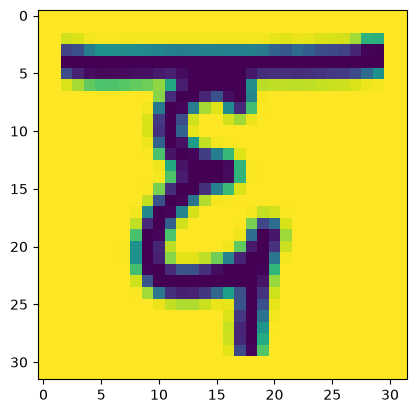

In [ ]:
img_path = "./data/test/10975.png"
predict_nepali_character(img_path,model,class_names)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Predicted Character: क (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Predicted Character: च (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Predicted Character: घ (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Predicted Character: ङ (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted Character: छ (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Predicted Character: झ (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Predicted Character: घ (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Predicted Character: ख (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Predicted Character: ज (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted Character: छ (Confidence: 100.00%)


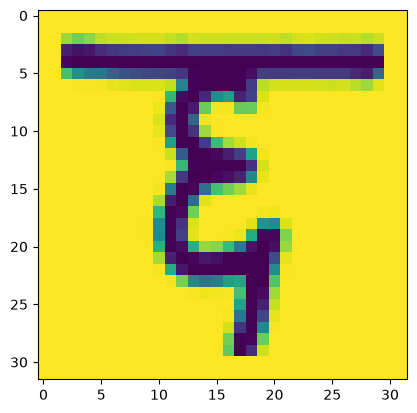

In [12]:
import os
folder_path = "./data/test"
for filename in os.listdir(folder_path):
    img_path = os.path.join(folder_path, filename)
    # with Image.open(img_path) as img:
    #     print(f"{filename}: Size (Width, Height) = {img.size}, Mode = {img.mode}")
    predict_nepali_character(img_path,model,class_names)
    # break  # Check the first image as a sample

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
छ


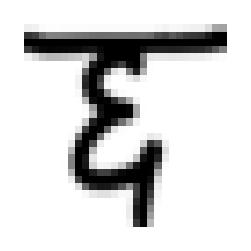

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

def display_and_predict(image_path, model, class_names):
    # 1. Load and preprocess image for the model
    img = load_img(image_path, target_size=(32, 32), color_mode="grayscale")
    img_array = img_to_array(img)
    normalized_array = img_array / 255.0
    input_tensor = np.expand_dims(normalized_array, axis=0) # Shape: (1, 32, 32, 1)
    
    # 2. Predict
    predictions = model.predict(input_tensor)
    predicted_index = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100
    predicted_char = class_names[predicted_index]
    print(predicted_char)
    
    # 3. Display using Matplotlib
    plt.figure(figsize=(3, 3))
    plt.imshow(img_array.squeeze(), cmap='gray')
    # plt.title(f"Pred: {predicted_char} ({confidence:.1f}%)", fontsize=25)
    plt.axis('off')
    plt.show()

# --- Run it ---
display_and_predict("./data/test/10975.png", model, class_names)

./data/test/129.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
क


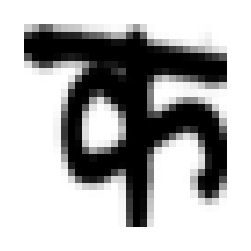

./data/test/9019.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
च


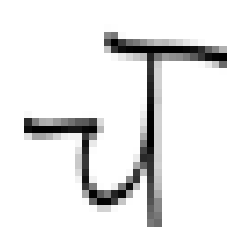

./data/test/5489.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
घ


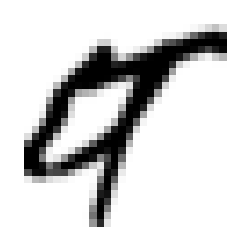

./data/test/7395.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
ङ


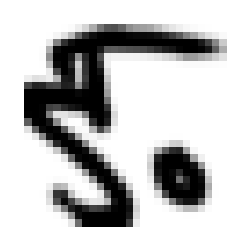

./data/test/10975.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
छ


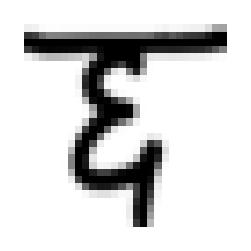

./data/test/14401.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
झ


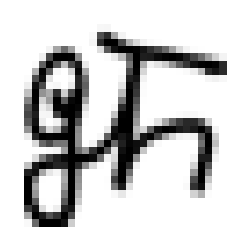

./data/test/5478.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
घ


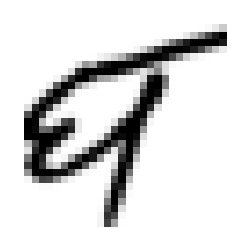

./data/test/1847.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
ख


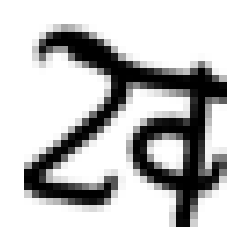

./data/test/12791.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
ज


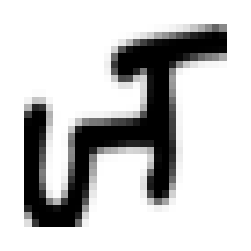

./data/test/10898.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
छ


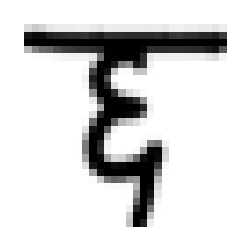

In [23]:
import os
folder_path = "./data/test"
for filename in os.listdir(folder_path):
    img_path = os.path.join(folder_path, filename)
    print(img_path)
    # with Image.open(img_path) as img:
    #     print(f"{filename}: Size (Width, Height) = {img.size}, Mode = {img.mode}")
    display_and_predict(img_path,model,class_names)
    # break  # Check the first image as a sample